# 3. Avaliação e uso no negócio

Um modelo só gera valor quando vira decisão. Neste notebook:

1. Entendemos a curva de precisão e recall
2. Verificamos se as probabilidades são confiáveis (calibração)
3. Medimos o desempenho por segmento
4. Traduzimos o modelo em decisões: quantos pedidos contatar e qual limiar usar
5. Interpretamos o que o modelo aprendeu
6. Listamos limitações e próximos passos

In [1]:
import sys
from pathlib import Path

# Encontra a raiz do projeto e coloca a pasta src no caminho de importação.
RAIZ = Path.cwd()
while not (RAIZ / "src").exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from olist import graficos as g

g.aplicar_estilo()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

import joblib
from sklearn.metrics import precision_recall_curve
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

from olist.dados import carregar_base
from olist import modelagem as m, negocio as n

base = m.preparar_tipos(carregar_base())
treino, teste = m.dividir_treino_teste(base)
X_teste, y_teste = teste[m.VARIAVEIS], teste[m.ALVO]

modelo = joblib.load(RAIZ / "models" / "gradient_boosting.joblib")
prob = modelo.predict_proba(X_teste)[:, 1]
print(m.avaliar(y_teste, prob).como_dict())

{'PR-AUC': 0.3444, 'ROC-AUC': 0.7264, 'Brier': 0.0804, 'Taxa base': 0.1033}


## 3.1 Curva de precisão e recall

O modelo devolve uma probabilidade para cada pedido. Para virar decisão, escolhemos um **limiar**: acima dele, o pedido é contatado. Cada limiar gera um par de precisão e recall:

- limiar alto: contatamos poucos pedidos, quase todos de risco real (precisão alta), mas deixamos muitas avaliações negativas passarem (recall baixo);
- limiar baixo: encontramos mais avaliações negativas, mas contatamos muita gente que estava satisfeita.

A curva mostra todas essas combinações. A PR-AUC é a área sob ela.

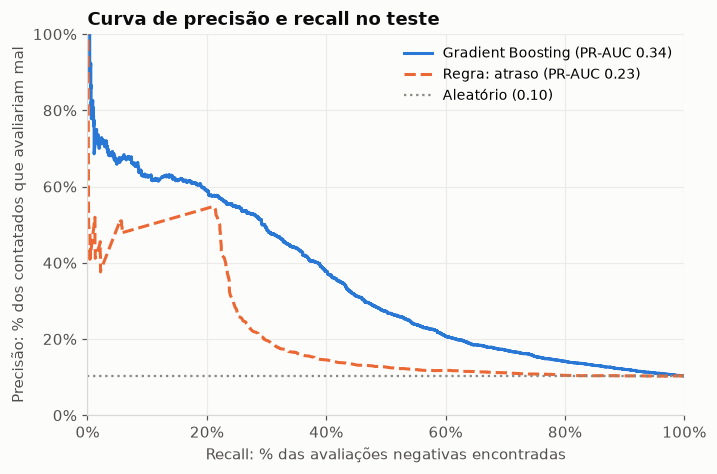

In [2]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for nome, score, cor, estilo in [
    ("Gradient Boosting", prob, g.AZUL, "-"),
    ("Regra: atraso", teste["dias_atraso_observado"], g.LARANJA, "--"),
]:
    precisao, recall, _ = precision_recall_curve(y_teste, score)
    ax.plot(recall, precisao, color=cor, linestyle=estilo, label=f"{nome} (PR-AUC {m.avaliar(y_teste, score).pr_auc:.2f})")
ax.axhline(y_teste.mean(), color=g.CINZA, linestyle=":", linewidth=1.5, label=f"Aleatório ({y_teste.mean():.2f})")
ax.set_xlabel("Recall: % das avaliações negativas encontradas")
ax.set_ylabel("Precisão: % dos contatados que avaliariam mal")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Curva de precisão e recall no teste")
ax.legend(loc="upper right", fontsize=9)
g.salvar(fig, "06_curva_precisao_recall")
plt.show()

No começo da curva (poucos pedidos contatados), o modelo passa de 60% de precisão até cerca de 20% de recall, seis vezes a taxa base. A regra de atraso tem um degrau: ela acerta bem os pedidos atrasados, mas depois disso não sabe diferenciar os pedidos no prazo, e a precisão despenca para perto do aleatório. (Os trechos retos da regra aparecem porque muitos pedidos têm exatamente o mesmo valor de atraso, e a ordem entre eles fica indefinida.)

## 3.2 As probabilidades são confiáveis?

Se o modelo diz "30% de chance", entre todos os pedidos com essa previsão, cerca de 30% deveriam avaliar mal. Isso é **calibração**. Ela importa porque o limiar por custo (seção 3.5) usa a probabilidade diretamente.

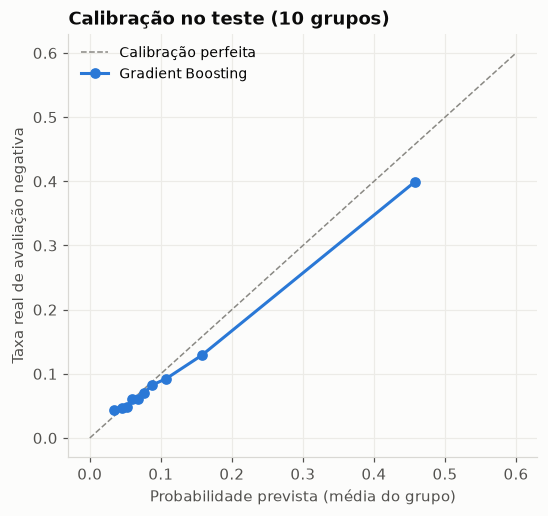

Probabilidade média prevista: 11.5%  |  Taxa real no teste: 10.3%


,prob. prevista,taxa real
0,0.034,0.044
1,0.045,0.046
2,0.053,0.048
3,0.060,0.060
4,0.067,0.061
5,0.076,0.070
6,0.088,0.082
7,0.108,0.093
8,0.158,0.129
9,0.457,0.399


In [3]:
taxa_real, prob_media = calibration_curve(y_teste, prob, n_bins=10, strategy="quantile")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 0.6], [0, 0.6], color=g.CINZA, linestyle="--", linewidth=1, label="Calibração perfeita")
ax.plot(prob_media, taxa_real, color=g.AZUL, marker="o", markersize=6, label="Gradient Boosting")
ax.set_xlabel("Probabilidade prevista (média do grupo)")
ax.set_ylabel("Taxa real de avaliação negativa")
ax.set_title("Calibração no teste (10 grupos)")
ax.legend(loc="upper left", fontsize=9)
g.salvar(fig, "07_calibracao")
plt.show()

print(f"Probabilidade média prevista: {prob.mean():.1%}  |  Taxa real no teste: {y_teste.mean():.1%}")
pd.DataFrame({"prob. prevista": prob_media, "taxa real": taxa_real}).round(3)

A calibração é boa nos grupos de risco baixo e médio. No grupo de maior risco, o modelo **superestima um pouco** (prevê cerca de 46% e a taxa real é cerca de 40%), e na média ele prevê um pouco acima da realidade.

Isso é consequência direta da mudança que vimos no notebook 2: o modelo aprendeu num período com mais atrasos (taxa de 13,5%) e foi testado num período melhor (10,3%). A **ordenação** dos pedidos continua boa, que é o que importa para escolher quem contatar primeiro. Para usar probabilidades em contas de custo, o ideal seria **recalibrar** periodicamente com dados recentes (por exemplo, com `CalibratedClassifierCV` num período mais novo).

## 3.3 Desempenho por segmento

O modelo funciona igualmente bem para pedidos entregues e não entregues na data da pesquisa?

In [4]:
segmentos = []
for nome, mascara in [("entregue antes da pesquisa", teste["entregue_antes_pesquisa"] == 1),
                      ("não entregue na pesquisa", teste["entregue_antes_pesquisa"] == 0)]:
    modelo_seg = m.avaliar(y_teste[mascara], prob[mascara])
    regra_seg = m.avaliar(y_teste[mascara], teste.loc[mascara, "dias_atraso_observado"])
    segmentos.append({"segmento": nome, "pedidos": int(mascara.sum()), "taxa base": modelo_seg.taxa_base,
                      "PR-AUC modelo": modelo_seg.pr_auc, "PR-AUC regra": regra_seg.pr_auc,
                      "lift do modelo": modelo_seg.pr_auc / modelo_seg.taxa_base})
pd.DataFrame(segmentos).set_index("segmento")

,pedidos,taxa base,PR-AUC modelo,PR-AUC regra,lift do modelo
segmento,,,,,
entregue antes da pesquisa,19255,0.086,0.202,0.085,2.358
não entregue na pesquisa,1595,0.315,0.634,0.574,2.014


Dois comportamentos diferentes:

- **Pedidos não entregues na pesquisa:** risco alto (cerca de 31% no teste), e o modelo ordena bem dentro desse grupo. A regra de atraso já ajuda aqui.
- **Pedidos entregues:** é o grupo difícil, e é onde o modelo mais agrega valor. A regra de atraso não serve para nada nesse grupo (PR-AUC igual à taxa base), enquanto o modelo mais que dobra a taxa base usando variáveis como número de itens, histórico do vendedor e categoria. São pedidos que "deram certo" na logística e mesmo assim recebem nota ruim, um risco que ninguém enxergaria sem o modelo.

## 3.4 Quantos pedidos contatar?

Na prática, o time de atendimento tem capacidade limitada. A pergunta real é: **"se dá para contatar X% dos pedidos, quais escolher e o que se ganha?"**

In [5]:
capacidade = n.tabela_capacidade(y_teste, prob)
capacidade

,% contatado,pedidos contatados,negativas encontradas,precisão,recall,lift,limiar de probabilidade
0,5%,1042,558,0.536,0.259,5.180,0.420
1,10%,2085,832,0.399,0.386,3.860,0.212
2,15%,3128,976,0.312,0.453,3.020,0.153
3,20%,4170,1101,0.264,0.511,2.560,0.123
4,30%,6255,1294,0.207,0.601,2.000,0.095


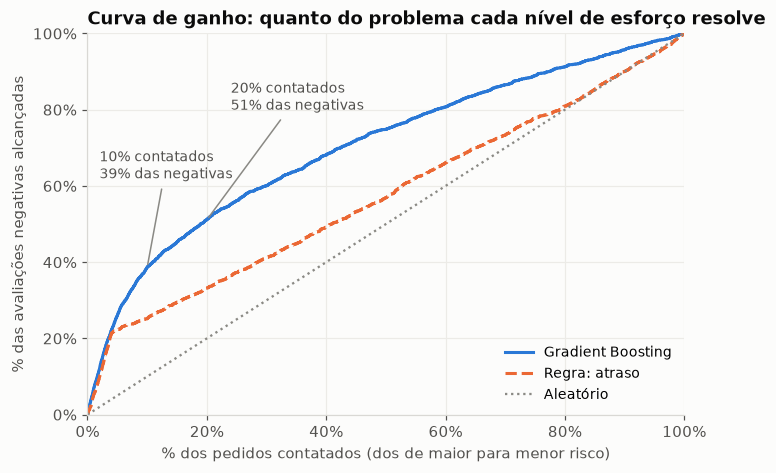

In [6]:
ordem = np.argsort(-prob)
recall_acumulado = np.cumsum(y_teste.values[ordem]) / y_teste.sum()
fracao = np.arange(1, len(prob) + 1) / len(prob)

ordem_regra = np.argsort(-teste["dias_atraso_observado"].values, kind="stable")
recall_regra = np.cumsum(y_teste.values[ordem_regra]) / y_teste.sum()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(fracao, recall_acumulado, color=g.AZUL, label="Gradient Boosting")
ax.plot(fracao, recall_regra, color=g.LARANJA, linestyle="--", label="Regra: atraso")
ax.plot([0, 1], [0, 1], color=g.CINZA, linestyle=":", linewidth=1.5, label="Aleatório")
for _, linha in capacidade.iterrows():
    if linha["% contatado"] in ("10%", "20%"):
        x = float(linha["% contatado"].strip("%")) / 100
        destino = {"10%": (0.02, 0.62), "20%": (0.24, 0.80)}[linha["% contatado"]]
        ax.annotate(f"{linha['% contatado']} contatados\n{linha['recall']:.0%} das negativas",
                    xy=(x, linha["recall"]), xytext=destino,
                    fontsize=9, color=g.TEXTO_SECUNDARIO,
                    arrowprops=dict(arrowstyle="-", color=g.CINZA, linewidth=1))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("% dos pedidos contatados (dos de maior para menor risco)")
ax.set_ylabel("% das avaliações negativas alcançadas")
ax.set_title("Curva de ganho: quanto do problema cada nível de esforço resolve")
ax.legend(loc="lower right", fontsize=9)
g.salvar(fig, "08_curva_ganho")
plt.show()

Como ler a tabela e o gráfico:

- **Contatando 10% dos pedidos**, o time alcança cerca de 38% de todas as avaliações negativas, com precisão perto de 40%: de cada 10 ligações, 4 são para clientes que iam avaliar mal. Ao acaso, seria 1 em cada 10.
- **O lift diminui conforme se contata mais gente**: os primeiros pedidos da lista são os mais certeiros. Por isso a decisão de capacidade é de negócio, não do modelo.

## 3.5 Qual limiar usar? Uma decisão pelo custo

Se soubermos quanto custa agir e quanto vale evitar uma avaliação negativa, dá para calcular o limiar ótimo. Contatar um pedido com probabilidade **p** de avaliação negativa:

- custa **C** (tempo do atendimento, eventual cupom);
- gera, em média, **p × e × V** de benefício, em que **V** é o valor de evitar uma avaliação negativa e **e** é a efetividade da ação (a fração de casos em que o contato realmente evita a nota ruim).

Vale a pena contatar quando o benefício esperado supera o custo:

**p × e × V > C, ou seja, p > C / (e × V)**

Os valores abaixo são **hipotéticos**, só para ilustrar o raciocínio. Num projeto real, eles viriam da área de negócio e de um teste A/B para medir a efetividade.

In [7]:
CUSTO_CONTATO = 4.0     # R$ por contato (hipotético)
VALOR_EVITADO = 40.0    # R$ de valor por avaliação negativa evitada (hipotético)
EFETIVIDADE = 0.25      # 25% dos contatos evitam a nota ruim (hipotético)

limiar = n.limiar_por_custo(CUSTO_CONTATO, VALOR_EVITADO, EFETIVIDADE)
print(f"Limiar ótimo: contatar pedidos com probabilidade acima de {limiar:.0%}")
pd.Series(n.resultado_esperado(y_teste, prob, limiar, CUSTO_CONTATO, VALOR_EVITADO, EFETIVIDADE), dtype=object)

Limiar ótimo: contatar pedidos com probabilidade acima de 40%


limiar                                0.400
pedidos contatados                     1085
% contatado                           0.052
negativas alcançadas                    575
negativas evitadas (estimativa)     143.800
custo (R$)                        4,340.000
benefício (R$)                    5,750.000
resultado (R$)                    1,410.000
dtype: object

E como o resultado muda se as premissas estiverem erradas? Uma **análise de sensibilidade** mostra o limiar e o resultado no teste para várias combinações:

In [8]:
sensibilidade = []
for custo in [2.0, 4.0, 8.0]:
    for efetividade in [0.15, 0.25, 0.40]:
        lim = n.limiar_por_custo(custo, VALOR_EVITADO, efetividade)
        r = n.resultado_esperado(y_teste, prob, lim, custo, VALOR_EVITADO, efetividade)
        sensibilidade.append({"custo (R$)": custo, "efetividade": f"{efetividade:.0%}", "limiar": f"{lim:.0%}",
                              "% contatado": f"{r['% contatado']:.1%}", "resultado no teste (R$)": int(round(r["resultado (R$)"]))})
pd.DataFrame(sensibilidade)

,custo (R$),efetividade,limiar,% contatado,resultado no teste (R$)
0,2.000,15%,33%,6.0%,1282
1,2.000,25%,20%,10.8%,4078
2,2.000,40%,12%,19.5%,9278
3,4.000,15%,67%,2.4%,-138
4,4.000,25%,40%,5.2%,1410
5,4.000,40%,25%,8.1%,5168
6,8.000,15%,133%,0.0%,0
7,8.000,25%,80%,0.2%,-30
8,8.000,40%,50%,4.2%,888


Quando a ação é cara ou pouco efetiva, o limiar sobe e o modelo recomenda contatar poucos pedidos, só os de risco muito alto. Quando é barata e efetiva, vale contatar mais gente. Em alguns cenários **nenhum contato compensa**, e isso também é uma resposta útil: mostra que antes de investir no modelo seria preciso baratear a ação ou torná-la mais efetiva.

Repare em dois cenários com **resultado negativo mesmo usando o limiar "ótimo"**. É a calibração da seção 3.2 aparecendo na prática: no grupo de maior risco, o modelo superestima a probabilidade, então a conta "acha" que o contato compensa quando na verdade não compensa. É o argumento concreto para recalibrar o modelo antes de usar probabilidades em decisões de custo.

**Por que não usar o limiar padrão de 0,5?** Porque 0,5 não tem nenhum significado de negócio. Neste problema, ele contataria só uma pequena fração dos pedidos, sem levar em conta custo nem capacidade do time.

## 3.6 O que o modelo aprendeu

### Importância por permutação

Para cada variável, embaralhamos seus valores no teste e medimos quanto a PR-AUC cai. Se cair muito, o modelo depende dessa variável. A vantagem sobre a "importância" padrão das árvores é que ela é medida no teste e na métrica que nos importa. Leva cerca de 1 minuto.

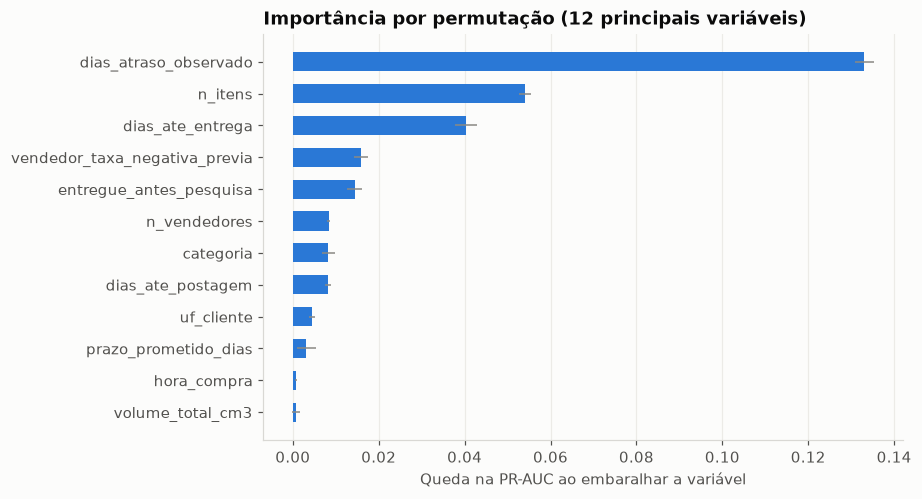

,queda na PR-AUC,desvio
dias_atraso_observado,0.133,0.002
n_itens,0.054,0.001
dias_ate_entrega,0.040,0.003
vendedor_taxa_negativa_previa,0.016,0.002
entregue_antes_pesquisa,0.014,0.002
n_vendedores,0.008,0.000
categoria,0.008,0.001
dias_ate_postagem,0.008,0.001
uf_cliente,0.004,0.001
prazo_prometido_dias,0.003,0.002


In [9]:
resultado_perm = permutation_importance(
    modelo, X_teste, y_teste, scoring="average_precision", n_repeats=5, random_state=m.SEMENTE, n_jobs=-1
)
importancia = (
    pd.DataFrame({"queda na PR-AUC": resultado_perm.importances_mean, "desvio": resultado_perm.importances_std},
                 index=m.VARIAVEIS)
    .sort_values("queda na PR-AUC", ascending=False)
)

top = importancia.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.barh(top.index, top["queda na PR-AUC"], xerr=top["desvio"], color=g.AZUL, height=0.6,
        error_kw=dict(ecolor=g.CINZA, lw=1))
ax.set_xlabel("Queda na PR-AUC ao embaralhar a variável")
ax.set_title("Importância por permutação (12 principais variáveis)")
ax.grid(axis="y", visible=False)
g.salvar(fig, "09_importancia")
plt.show()
importancia.head(12)

### Como cada variável afeta o risco

O gráfico de **dependência parcial** mostra como a probabilidade prevista muda quando variamos uma variável e mantemos as outras como estão.

Um detalhe técnico: para o Gradient Boosting, o scikit-learn usa por padrão um cálculo rápido (`method="recursion"`) que mostra o resultado em log-odds e, neste modelo, chegou a esconder o efeito do histórico do vendedor. Usamos o cálculo direto (`method="brute"`), que é mais lento mas mede a probabilidade de verdade. Vale sempre conferir se um gráfico de interpretação faz sentido com o que os dados mostram.

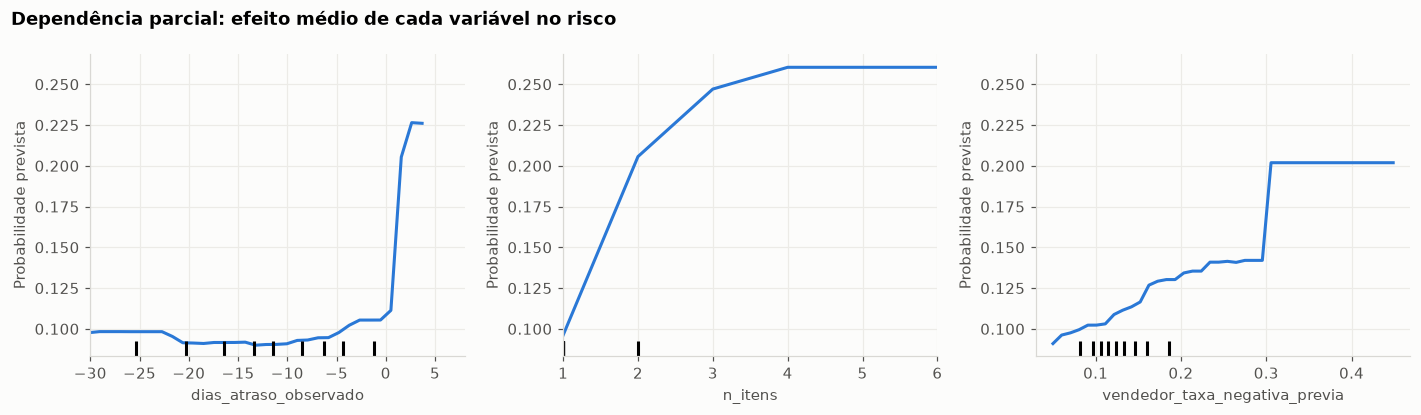

In [10]:
# O gráfico exige variáveis numéricas em ponto flutuante (n_itens é inteiro).
amostra = X_teste.sample(5000, random_state=m.SEMENTE)
amostra[m.NUMERICAS] = amostra[m.NUMERICAS].astype(float)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
PartialDependenceDisplay.from_estimator(
    modelo, amostra,
    ["dias_atraso_observado", "n_itens", "vendedor_taxa_negativa_previa"],
    ax=axes, line_kw={"color": g.AZUL}, grid_resolution=40,
    method="brute", response_method="predict_proba", percentiles=(0.01, 0.995),
)
axes[0].set_xlim(-30, 8)
axes[1].set_xlim(1, 6)
for ax in axes:
    ax.set_ylabel("Probabilidade prevista")
fig.suptitle("Dependência parcial: efeito médio de cada variável no risco", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
g.salvar(fig, "10_dependencia_parcial")
plt.show()

O modelo aprendeu exatamente o que a análise exploratória sugeria, o que dá confiança de que ele não está capturando ruído:

1. **Atraso observado** é a variável dominante, com um salto quando o prazo é ultrapassado (perto de zero no eixo).
2. **Número de itens** aumenta o risco de forma consistente, coerente com a hipótese de entrega parcial.
3. **Histórico do vendedor** tem efeito crescente: quanto pior o histórico, maior o risco.

## 3.7 Limitações

- **Só pedidos entregues.** Pedidos cancelados ou indisponíveis ficaram fora; eles têm dinâmica própria e mereceriam outro modelo.
- **Mudança no tempo.** O desempenho caiu do período de validação para o de teste; em produção, o modelo precisaria de monitoramento e retreino periódico.
- **Calibração.** As probabilidades ficaram um pouco altas no teste; contas de custo exigiriam recalibração com dados recentes.
- **Efeito da ação é desconhecido.** O modelo diz quem tem risco, não se o contato funciona. Isso só se mede com um **teste A/B**: contatar metade dos pedidos de alto risco e comparar com a outra metade.
- **Entrega parcial é hipótese.** Os dados não têm a data de entrega de cada item para confirmar.

## 3.8 Próximos passos

1. Desenhar o teste A/B para medir a efetividade do contato.
2. Recalibrar as probabilidades com uma janela recente.
3. Incluir texto de reclamações anteriores do cliente ou do vendedor (NLP) como variável, sempre respeitando o momento da previsão.
4. Monitorar mensalmente a PR-AUC e a taxa base, com alerta de *drift*.